# Aula 01 · Fundamentos e propagação direta

Vamos usar os mesmos dois sensores para calcular a saída de um perceptron e, depois, de uma rede multicamadas. Cada sensor vale 1 quando detecta presença e 0 quando não detecta.

Cada linha da tabela é uma observação. As colunas de alvo registram as respostas esperadas para OR, AND e XOR. Para montar `X`, selecionamos apenas as duas leituras.

In [1]:
import numpy as np
import pandas as pd

dados = pd.DataFrame({
    "sensor_a": [0, 0, 1, 1],
    "sensor_b": [0, 1, 0, 1],
    "alvo_or": [0, 1, 1, 1],
    "alvo_and": [0, 0, 0, 1],
    "alvo_xor": [0, 1, 1, 0],
})

X = dados[["sensor_a", "sensor_b"]].to_numpy(dtype=np.float32)
dados

,sensor_a,sensor_b,alvo_or,alvo_and,alvo_xor
0,0,0,0,0,0
1,0,1,1,0,1
2,1,0,1,0,1
3,1,1,1,1,0


## 01 · Neurônio e perceptron em NumPy

O símbolo `@` calcula o produto entre entradas e pesos. Somamos o viés para obter `z`. Sobre o mesmo `z`, a ReLU usa `max(0, z)` e o perceptron usa o degrau, que devolve 1 quando `z ≥ 0`.

In [2]:
w = np.array([0.2, 0.2], dtype=np.float32)

x = X[1]

print(f"x: {x}")

x: [0. 1.]


In [3]:
b = -0.3
z = x @ w + b

print("Sensores", x)
print(f"Soma com viés {z:.2f}")
print("Degrau", int(z >= 0))

Sensores [0. 1.]
Soma com viés -0.10
Degrau 0


Com os mesmos pesos, mover a fronteira de decisão muda a regra. O viés −0,1 implementa OR e o viés −0,3 implementa AND. A tabela da próxima célula mostra a soma com viés e a classe para cada combinação dos sensores.

<img src="figuras/portas_logicas_or_and.png" alt="As fronteiras de decisão de OR e AND nos quatro pares de sensores" width="700">

In [4]:
b_or = -0.1
b_and = -0.3

# Somamos os produtos uma vez e aplicamos o viés de cada regra.
soma = X @ w
z_or = soma + b_or
z_and = soma + b_and

# A função degrau devolve 1 para uma soma com viés igual ou maior que zero.
saida_or = (z_or >= 0).astype(int)
saida_and = (z_and >= 0).astype(int)

print(
    "A saída do OR e o alvo são",
    "iguais." if np.array_equal(saida_or, dados["alvo_or"]) else "diferentes.",
)
print(
    "A saída do AND e o alvo são",
    "iguais." if np.array_equal(saida_and, dados["alvo_and"]) else "diferentes.",
)

dados[["sensor_a", "sensor_b"]].assign(
    z_or=z_or.round(2),
    classe_or=saida_or,
    z_and=z_and.round(2),
    classe_and=saida_and,
)

A saída do OR e o alvo são iguais.
A saída do AND e o alvo são iguais.


,sensor_a,sensor_b,z_or,classe_or,z_and,classe_and
0,0,0,-0.1,0,-0.3,0
1,0,1,0.1,1,-0.1,0
2,1,0,0.1,1,-0.1,0
3,1,1,0.3,1,0.1,1


### Perceptron do scikit-learn

Com a função `fit`, o perceptron aprende os pesos e o viés a partir dos alvos da tabela. Vamos comparar as classes previstas nas mesmas quatro observações usadas no ajuste. As retas da figura correspondem à escolha manual de pesos e vieses.

In [5]:
from sklearn.linear_model import Perceptron

modelo_or = Perceptron().fit(X, dados["alvo_or"])
modelo_and = Perceptron().fit(X, dados["alvo_and"])

In [6]:
saida_or_sklearn = modelo_or.predict(X)
saida_and_sklearn = modelo_and.predict(X)

In [7]:
print(
    "As saídas do OR em NumPy e scikit-learn são",
    "iguais." if np.array_equal(saida_or_sklearn, saida_or) else "diferentes.",
)
print(
    "As saídas do AND em NumPy e scikit-learn são",
    "iguais." if np.array_equal(saida_and_sklearn, saida_and) else "diferentes.",
)

dados[["sensor_a", "sensor_b"]].assign(
    or_numpy=saida_or,
    or_sklearn=saida_or_sklearn,
    and_numpy=saida_and,
    and_sklearn=saida_and_sklearn,
)

As saídas do OR em NumPy e scikit-learn são iguais.
As saídas do AND em NumPy e scikit-learn são iguais.


,sensor_a,sensor_b,or_numpy,or_sklearn,and_numpy,and_sklearn
0,0,0,0,0,0,0
1,0,1,1,1,0,0
2,1,0,1,1,0,0
3,1,1,1,1,1,1


## 02 · XOR camada por camada em NumPy

O alvo é 1 quando os sensores divergem. A rede tem duas entradas, dois neurônios ocultos com ReLU e uma saída linear. Os pesos e vieses foram escolhidos para construir o XOR.

<img src="figuras/porta_logica_xor.png" alt="Tabela-verdade do XOR com as classes nos cantos opostos" width="700">

### Arquitetura de uma MLP

O slide 21 mostra a arquitetura geral usada neste exemplo. Cada neurônio oculto calcula uma soma com viés $z_j$ e aplica uma função de ativação para obter $h_j=\phi(z_j)$. A camada de saída combina as ativações. No XOR, usaremos a ReLU como $\phi$.

<img src="figuras/mlp_2_2_1_arquitetura_geral.png" alt="Arquitetura geral de uma MLP com duas entradas, dois neurônios ocultos e uma saída linear" width="720">

In [8]:
y = dados[["alvo_xor"]].to_numpy(dtype=np.float32)

W1 = np.array([[1, 1],
               [1, 1]], dtype=np.float32)
b1 = np.array([0, -1], dtype=np.float32)

W2 = np.array([[1],
               [-2]], dtype=np.float32)
b2 = np.array([0], dtype=np.float32)

### Um exemplo com os dois sensores ativos

Vamos aplicar a arquitetura do slide 21 ao caso em que os dois sensores valem 1. A primeira soma com viés é $1+1+0=2$ e a segunda é $1+1-1=1$. A ReLU mantém os dois valores positivos, então $h_1=2$ e $h_2=1$. A saída linear fica $\hat{y}=2-2\times 1=0$, como esperado no XOR quando os sensores concordam.

<img src="figuras/mlp_2_2_1_xor_exemplo_11_externo.png" alt="Cálculo das ativações e da saída do XOR para A igual a 1 e B igual a 1" width="680">

In [9]:
# A última linha de X contém o par (1, 1) deste exemplo.
x_11 = X[-1]
print("Sensores", x_11)

Sensores [1. 1.]


In [10]:
z_11 = x_11 @ W1 + b1
print("Somas com viés", z_11)

Somas com viés [2. 1.]


In [11]:
h_11 = np.maximum(0, z_11)
print("Ativações", h_11)

Ativações [2. 1.]


In [12]:
saida_11 = (h_11 @ W2 + b2).item()

print("Saída", saida_11)

Saída 0.0


### Os quatro casos de XOR

Agora fazemos a mesma conta para todas as observações. Cada linha de X contém um par de sensores e cada coluna de W1 contém os pesos de um neurônio oculto. Em Z1 e H, as linhas correspondem aos quatro pares e as colunas a $h_1$ e $h_2$. A rede devolve uma saída por observação.

In [13]:
Z1 = X @ W1 + b1
H = np.maximum(0, Z1)
saida = H @ W2 + b2

print(f"Antes da ReLU {Z1.shape}\n{Z1}")
print(f"Depois da ReLU {H.shape}\n{H}")
print(f"Saída da rede {saida.shape}\n{saida.ravel()}")


Antes da ReLU (4, 2)
[[ 0. -1.]
 [ 1.  0.]
 [ 1.  0.]
 [ 2.  1.]]
Depois da ReLU (4, 2)
[[0. 0.]
 [1. 0.]
 [1. 0.]
 [2. 1.]]
Saída da rede (4, 1)
[0. 1. 1. 0.]


### Classes previstas no XOR

A saída numérica da rede é $\hat{y}$. Para obter a classe, usamos 1 quando $\hat{y}\geq 0{,}5$ e 0 nos demais casos. A tabela mostra o alvo, a saída e a classe para cada par de sensores.

In [14]:
classe_xor = (saida.ravel() >= 0.5).astype(int)

print(
    "As classes do XOR com ReLU e o alvo são",
    "iguais." if np.array_equal(classe_xor, y.ravel()) else "diferentes.",
)

dados[["sensor_a", "sensor_b", "alvo_xor"]].assign(
    saida_relu=saida.ravel(),
    classe_relu=classe_xor,
)

As classes do XOR com ReLU e o alvo são iguais.


,sensor_a,sensor_b,alvo_xor,saida_relu,classe_relu
0,0,0,0,0.0,0
1,0,1,1,1.0,1
2,1,0,1,1.0,1
3,1,1,0,0.0,0


### Fronteiras de decisão

Os dois painéis do slide 22 mostram os quatro casos do XOR. À esquerda, uma tentativa com fronteira linear coloca $(1,1)$ na região da classe 1, embora seu alvo seja 0. À direita, a faixa de decisão da MLP com ReLU reúne os dois casos em que os sensores discordam, $(0,1)$ e $(1,0)$.

<img src="figuras/relu_nao_linearidade_xor.png" alt="Tentativa linear para o XOR e faixa de decisão do XOR com ReLU" width="760">

### Fronteiras calculadas em NumPy

A célula seguinte mostra as três regras numa grade de valores dos sensores. O tracejado marca $z=0$ no OR e no AND. No XOR com ReLU, marca o limiar de $0{,}5$ aplicado à saída da rede.

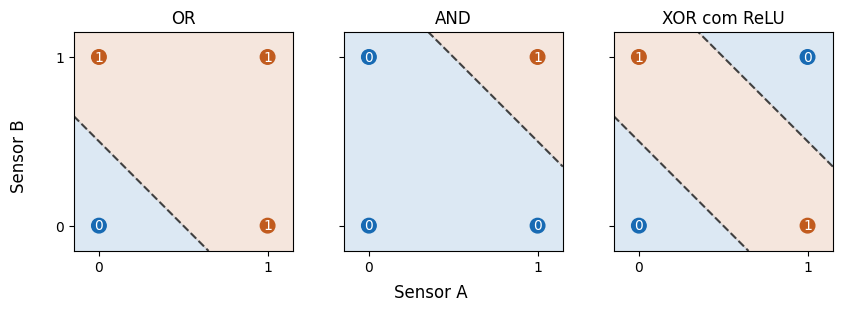

In [15]:
import matplotlib.pyplot as plt

# Avaliamos cada regra em uma grade de valores dos dois sensores.
eixo = np.linspace(-0.15, 1.15, 200, dtype=np.float32)
A, B = np.meshgrid(eixo, eixo)
grade = np.column_stack([A.ravel(), B.ravel()])

soma_grade = grade @ w
H_grade = np.maximum(0, grade @ W1 + b1)
xor_grade = H_grade @ W2 + b2

paineis = [
    ("OR", soma_grade + b_or, 0, saida_or),
    ("AND", soma_grade + b_and, 0, saida_and),
    ("XOR com ReLU", xor_grade, 0.5, classe_xor),
]

cores = ["#176ab3", "#c15b1e"]
fig, eixos = plt.subplots(1, 3, figsize=(8.5, 3), sharex=True, sharey=True, layout="constrained")

for ax, (titulo, valores, limiar, classes) in zip(eixos, paineis):
    valores = valores.reshape(A.shape)
    ax.contourf(A, B, valores >= limiar, levels=[-0.5, 0.5, 1.5], colors=cores, alpha=0.15)
    ax.contour(A, B, valores, levels=[limiar], colors="0.25", linestyles="--")
    ax.scatter(X[:, 0], X[:, 1], c=[cores[classe] for classe in classes], s=110, zorder=3)
    for (sensor_a, sensor_b), classe in zip(X, classes):
        ax.text(sensor_a, sensor_b, str(classe), ha="center", va="center", color="white", zorder=4)
    ax.set(title=titulo, xticks=[0, 1], yticks=[0, 1], aspect="equal")

fig.supxlabel("Sensor A")
fig.supylabel("Sensor B")
plt.show()

## 03 · A mesma rede em Keras

Voltamos ao XOR dos sensores. Vamos copiar os pesos do NumPy para conferir a propagação direta em Keras. Cada camada Dense multiplica as entradas pelos pesos e soma os vieses. A camada oculta aplica ReLU e tem seis parâmetros. A camada de saída é linear e tem três parâmetros.

<img src="figuras/mlp_2_2_1_xor.png" alt="Rede XOR com duas entradas, dois neurônios ReLU e uma saída linear" width="500">

In [16]:
from tensorflow import keras

modelo = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(2, activation="relu"),
    keras.layers.Dense(1),
])
modelo.set_weights([W1, b1, W2, b2])

In [17]:
modelo.summary()
print("Parâmetros", modelo.count_params())

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 9 (36.00 B)
 Trainable params: 9 (36.00 B)
 Non-trainable params: 0 (0.00 B)
Parâmetros 9


In [18]:
saida_keras = modelo(X).numpy()

print("Saída em Keras", saida_keras.ravel())

Saída em Keras [0. 1. 1. 0.]


### Perda quadrática média

No slide 30, somamos os erros quadráticos das dez saídas para um único dígito. A soma é $1{,}0246$. Se dividíssemos pelas dez saídas, a média seria $0{,}10246$.

No XOR, cada par de sensores tem uma saída. Calculamos a média dos erros quadráticos sobre os quatro pares:

$$
\operatorname{MSE} = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)^2
$$

Aqui, $n=4$, $\hat{y}_i$ é a saída numérica e $y_i$ é o alvo do XOR. Comparamos o MSE da rede com ReLU em NumPy e Keras.

In [19]:
perda_relu = np.mean((saida - y) ** 2)
perda_relu_keras = np.mean((saida_keras - y) ** 2)

pd.DataFrame({
    "Implementação": ["NumPy", "Keras"],
    "Ativação": ["ReLU", "ReLU"],
    "MSE": [perda_relu, perda_relu_keras],
})

,Implementação,Ativação,MSE
0,NumPy,ReLU,0.0
1,Keras,ReLU,0.0
